<a href="https://colab.research.google.com/github/AbdiRaqiibMohummed/CMP6202-coursework/blob/main/7_Tue_Nov_26.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [6]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, KFold, StratifiedKFold, cross_val_score
from sklearn.ensemble import RandomForestClassifier, RandomForestRegressor
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.dummy import DummyClassifier, DummyRegressor
from sklearn.model_selection import GridSearchCV, RandomizedSearchCV

from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.metrics import accuracy_score

In [5]:
df = pd.read_csv('/content/drive/MyDrive/CMP6202/datasets/Heart.csv')

In [4]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
df.head(2)

,Unnamed: 0,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,1,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No
1,2,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes


In [7]:
df.drop(columns = ['Unnamed: 0'], axis=1, inplace=True)

In [ ]:
from sklearn.preprocessing import LabelEncoder

In [ ]:
df.isna().sum()

,0
Age,0
Sex,0
ChestPain,0
RestBP,0
Chol,0
Fbs,0
RestECG,0
MaxHR,0
ExAng,0
Oldpeak,0


In [ ]:
df.dropna(inplace = True)

In [ ]:
df.isna().sum()

,0
Age,0
Sex,0
ChestPain,0
RestBP,0
Chol,0
Fbs,0
RestECG,0
MaxHR,0
ExAng,0
Oldpeak,0


In [ ]:
df.head(2)

,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,63,1,typical,145,233,1,2,150,0,2.3,3,0.0,fixed,No
1,67,1,asymptomatic,160,286,0,2,108,1,1.5,2,3.0,normal,Yes


In [ ]:
le = LabelEncoder()

In [ ]:
df.columns.tolist()

['Age',
 'Sex',
 'ChestPain',
 'RestBP',
 'Chol',
 'Fbs',
 'RestECG',
 'MaxHR',
 'ExAng',
 'Oldpeak',
 'Slope',
 'Ca',
 'Thal',
 'AHD']

In [ ]:
df['ChestPain'] = le.fit_transform(df['ChestPain'])
df['Thal'] = le.fit_transform(df['Thal'])
df['AHD'] = le.fit_transform(df['AHD'])

In [ ]:
df.head(2)

,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal,AHD
0,63,1,3,145,233,1,2,150,0,2.3,3,0.0,0,0
1,67,1,0,160,286,0,2,108,1,1.5,2,3.0,1,1


In [ ]:
X = df.drop(columns=['AHD'])
y = df['AHD']

In [ ]:
X.head(2)

,Age,Sex,ChestPain,RestBP,Chol,Fbs,RestECG,MaxHR,ExAng,Oldpeak,Slope,Ca,Thal
0,63,1,3,145,233,1,2,150,0,2.3,3,0.0,0
1,67,1,0,160,286,0,2,108,1,1.5,2,3.0,1


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [ ]:
skf = StratifiedKFold(n_splits= 5, shuffle= True, random_state=42)

In [ ]:
baseline = DummyClassifier(strategy = 'most_frequent', random_state=42)

In [ ]:
baseline_scores = cross_val_score(baseline, X_train, y_train, cv= skf, scoring ='accuracy')

In [ ]:
baseline_scores

array([0.52083333, 0.52083333, 0.53191489, 0.53191489, 0.5106383 ])

In [ ]:
baseline_mean = baseline_scores.mean().round(2)

# Decision Tree

In [ ]:
dt = DecisionTreeClassifier()

In [ ]:
skf = StratifiedKFold(n_splits= 5, shuffle= True, random_state=42)
tree_scores = cross_val_score(dt, X_train, y_train, cv= skf, scoring ='accuracy')
tree_mean = tree_scores.mean().round(2)

In [ ]:
print(tree_mean)

0.69


# RandomForest

In [ ]:
rf = RandomForestClassifier(random_state=42)
skf = StratifiedKFold(n_splits= 5, shuffle= True, random_state= 42)
rf_scores = cross_val_score(rf, X_train, y_train, cv=skf, scoring ='accuracy')

In [ ]:
rf_mean = rf_scores.mean().round(2)

In [ ]:
print(rf_mean)

0.81


In [ ]:
models = pd.DataFrame({
    'model': ['Dummy', 'Decision Tree', 'RandomForest'],
    'mean' : [baseline_mean, tree_mean, rf_mean]
})

In [ ]:
models.sort_values(by ='mean', ascending=False)

,model,mean
2,RandomForest,0.81
1,Decision Tree,0.69
0,Dummy,0.52


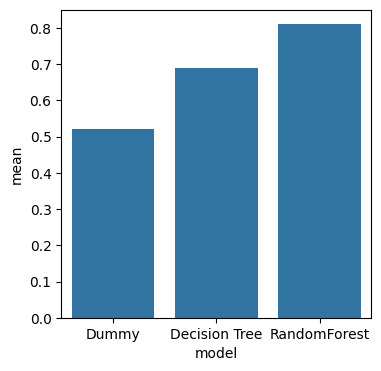

In [ ]:
plt.figure(figsize = (4,4))
sns.barplot(data = models, x ='model', y ='mean')
plt.show()

# FineTuning

In [ ]:
from sklearn.model_selection import GridSearchCV

In [ ]:
param_grid = {
    'n_estimators' : [100, 200, 300],
    'max_depth': [1,4,5]
}

In [ ]:
rf_grid = GridSearchCV(rf, param_grid= param_grid, scoring ='accuracy', cv=skf)

In [ ]:
rf_grid

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=RandomForestClassifier(random_state=42),
             param_grid={'max_depth': [1, 4, 5],
                         'n_estimators': [100, 200, 300]},
             scoring='accuracy')

In [ ]:
rf_grid.fit(X_train, y_train)

GridSearchCV(cv=StratifiedKFold(n_splits=5, random_state=42, shuffle=True),
             estimator=RandomForestClassifier(random_state=42),
             param_grid={'max_depth': [1, 4, 5],
                         'n_estimators': [100, 200, 300]},
             scoring='accuracy')

In [ ]:
rf_best= rf_grid.best_estimator_

In [ ]:
rf_grid.best_params_

{'max_depth': 1, 'n_estimators': 100}

In [ ]:
y_pred = rf_best.predict(X_test)

In [ ]:
rf_tuned_accuracy= np.round(accuracy_score(y_pred, y_test),2)

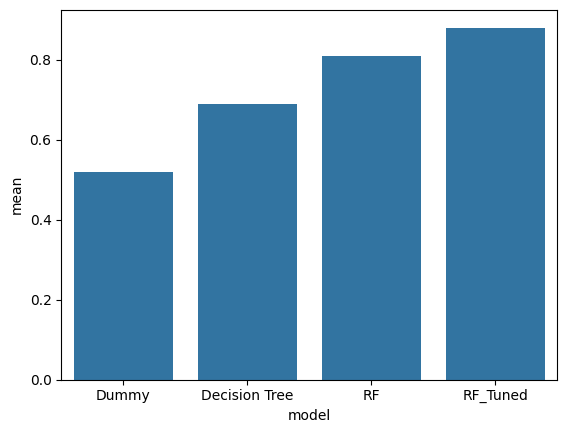

In [ ]:
models = pd.DataFrame({
    'model': ['Dummy', 'Decision Tree', 'RF', 'RF_Tuned' ],
    'mean' : [baseline_mean, tree_mean, rf_mean, rf_tuned_accuracy]
})

models.sort_values(by ='mean', ascending=False)

# plt.figure(figsize = (4,4))
sns.barplot(data = models, x ='model', y ='mean')
plt.show()